# Code 4: Variational quantum eigensolver (VQE) for HeH⁺

This notebook goes with [Lecture 4](../content/lectures/lecture4.md). We find the ground-state energy of the HeH⁺ molecule at a fixed separation $R$, using the two-qubit Hamiltonian from the lecture notes and the 8-parameter ansatz with a CZ gate.

The VQE loop is the same as in Code 3:

1. prepare the ansatz state $|\psi(\vec\theta)\rangle$,
2. **measure** the energy $E(\vec\theta) = \langle\psi(\vec\theta)|H|\psi(\vec\theta)\rangle$,
3. estimate $\nabla E$ by finite differences and take a gradient-descent step,
4. repeat.

The Hamiltonian data is in [`data/HamiltonianParameters.txt`](data/HamiltonianParameters.txt), which comes with the course code. If the notebook can't find it, it downloads the file automatically.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorSampler, StatevectorEstimator

## The Hamiltonian

Each row of the data file is

`R   c_11  c_1X  c_1Z  c_X1  c_XX  c_XZ  c_Z1  c_ZX  c_ZZ`

where $R$ is the separation in pm, and $c_{AB}$ is the coefficient of $A\otimes B$ (in Hartree), with $A$ acting on qubit 0 and $B$ on qubit 1. The Hamiltonian is

$$
H = \frac12 \sum_{A,B\in\{1,X,Z\}} c_{AB}\, A\otimes B .
$$

For almost every $R$ the coefficients are symmetric ($c_{X1}=c_{1X}$ etc.), which gives the more compact form in the lecture notes. We build the general form anyway, because it is no more work and makes no assumptions.

```{important}
Qiskit Pauli labels are read **right to left**: in `"XZ"` the `Z` acts on qubit 0 and the `X` on qubit 1. So $A\otimes B$ (with $A$ on qubit 0) is the Qiskit label `B + A`.
```

In [2]:
DATA_URL = ("https://raw.githubusercontent.com/UoN-PHYS4041/UoN-PHYS4041.github.io/"
            "main/notebooks/data/HamiltonianParameters.txt")
try:
    parameters = np.loadtxt("data/HamiltonianParameters.txt")
except FileNotFoundError:                       # no local copy: fetch it from the course repository
    import urllib.request
    with urllib.request.urlopen(DATA_URL) as f:
        parameters = np.loadtxt(f)
paulis = ["I", "X", "Z"]

def hamiltonian(R):
    # The two-qubit HeH+ Hamiltonian at separation R (pm), as a SparsePauliOp.
    row = parameters[parameters[:, 0] == R]
    if len(row) == 0:
        raise ValueError(f"No data for R = {R}. Available: {parameters[:, 0]}")
    coeffs = row[0, 1:]
    terms = []
    for k, c in enumerate(coeffs):
        A, B = paulis[k // 3], paulis[k % 3]      # A on qubit 0, B on qubit 1
        terms.append((B + A, c / 2))             # Qiskit label is reversed
    return SparsePauliOp.from_list(terms).simplify()

R = 90
H = hamiltonian(R)
print(H)

SparsePauliOp(['II', 'XI', 'ZI', 'IX', 'XX', 'ZX', 'IZ', 'XZ', 'ZZ'],
              coeffs=[-1.92525+0.j, -0.1144 +0.j, -0.5233 +0.j, -0.1144 +0.j,  0.13065+0.j,
  0.1144 +0.j, -0.5233 +0.j,  0.1144 +0.j,  0.1178 +0.j])


For two qubits $H$ is just a $4\times 4$ matrix, so we can find the exact ground-state energy by diagonalising it. This lets us check our VQE result. Of course, the whole point of VQE is for problems where this is impossible.

In [3]:
E_exact = np.linalg.eigvalsh(H.to_matrix()).min()
print(f"Exact ground-state energy at R = {R} pm:  E0 = {E_exact:.4f} Hartree")

Exact ground-state energy at R = 90 pm:  E0 = -2.8626 Hartree


## The ansatz

$R_X R_Z$ on each qubit, a CZ to entangle, then $R_X R_Z$ again: eight angles in total.

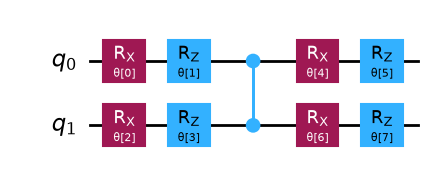

In [4]:
theta = ParameterVector("θ", 8)

ansatz = QuantumCircuit(2)
ansatz.rx(theta[0], 0); ansatz.rz(theta[1], 0)
ansatz.rx(theta[2], 1); ansatz.rz(theta[3], 1)
ansatz.cz(0, 1)                                  # entangling gate
ansatz.rx(theta[4], 0); ansatz.rz(theta[5], 0)
ansatz.rx(theta[6], 1); ansatz.rz(theta[7], 1)
ansatz.draw("mpl")

## Measuring the energy by hand

$H$ contains the Pauli strings $Z1, 1Z, ZZ, X1, 1X, XX, XZ, ZX$. Following the lecture, we measure in **four bases**, by applying $H$ gates to the qubits we want to measure in $X$:

| basis (qubit 0, qubit 1) | gives |
|---|---|
| Z, Z | $\langle Z1\rangle, \langle 1Z\rangle, \langle ZZ\rangle$ |
| Z, X | $\langle ZX\rangle$ |
| X, Z | $\langle XZ\rangle$ |
| X, X | $\langle X1\rangle, \langle 1X\rangle, \langle XX\rangle$ |

For a measured bit string, the eigenvalue of a product of $Z$s is $(-1)^{\text{(sum of the measured bits)}}$, so for example $\langle ZZ\rangle = p_{00} - p_{01} - p_{10} + p_{11}$.

In [5]:
def measurement_circuit(basis):
    # Ansatz followed by a basis change. basis = (basis of qubit 0, basis of qubit 1), e.g. ('X', 'Z').
    qc = ansatz.copy()
    for q, b in enumerate(basis):
        if b == "X":
            qc.h(q)
    qc.measure_all()
    return qc

def expectation_from_counts(counts, qubits):
    # <product of Z on `qubits`> from counts. Bit strings are q1 q0 (right to left!).
    shots = sum(counts.values())
    total = 0
    for bits, n in counts.items():
        parity = sum(int(bits[-1 - q]) for q in qubits)    # bits[-1] is qubit 0
        total += (-1) ** parity * n
    return total / shots

BASES = [("Z", "Z"), ("Z", "X"), ("X", "Z"), ("X", "X")]
measurement_circuits = [measurement_circuit(b) for b in BASES]

def energy_from_counts(counts_list):
    # Combine the counts from the four measurement bases into the energy.
    zz, zx, xz, xx = counts_list
    ev = {                                # keys: (A on qubit 0) + (B on qubit 1), as in the notes
        "Z1": expectation_from_counts(zz, [0]), "1Z": expectation_from_counts(zz, [1]),
        "ZZ": expectation_from_counts(zz, [0, 1]),
        "ZX": expectation_from_counts(zx, [0, 1]), "XZ": expectation_from_counts(xz, [0, 1]),
        "X1": expectation_from_counts(xx, [0]), "1X": expectation_from_counts(xx, [1]),
        "XX": expectation_from_counts(xx, [0, 1]),
    }
    c = dict(zip([a + b for a in "1XZ" for b in "1XZ"], parameters[parameters[:, 0] == R][0, 1:]))
    return c["11"] / 2 + sum(c[k] / 2 * v for k, v in ev.items())

def energy_by_hand(angles, sampler=StatevectorSampler(seed=1), circuits=measurement_circuits, shots=8192):
    res = sampler.run([(c, angles) for c in circuits], shots=shots).result()
    return energy_from_counts([r.data.meas.get_counts() for r in res])

angles_test = 2 * np.pi * np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
print(f"E(test angles), by hand:  {energy_by_hand(angles_test):.4f}")

E(test angles), by hand:  -1.0753


### The same thing with the Estimator

The Estimator does all of this for us: we give it the circuit (no measurements) and the `SparsePauliOp`. Its `precision` option adds the statistical noise you would get from a finite number of shots, about $1/\sqrt{\text{shots}}$.

In [6]:
estimator = StatevectorEstimator(seed=4041)

def energy(angle_sets, shots=8192):
    # Energies for an array of angle sets with shape (N, 8). shots=None gives exact values.
    precision = 0.0 if shots is None else 1 / np.sqrt(shots)
    return estimator.run([(ansatz, H, np.atleast_2d(angle_sets))], precision=precision).result()[0].data.evs

print(f"E(test angles), Estimator with shot noise: {energy(angles_test)[0]:.4f}")
print(f"E(test angles), exact:                     {energy(angles_test, shots=None)[0]:.4f}")

E(test angles), Estimator with shot noise: -1.0803
E(test angles), exact:                     -1.0830


The hand-made and Estimator values agree to within shot noise. From now on we use the Estimator.

## Gradient descent

Each iteration we evaluate $E$ at $\vec\theta$ and at the 16 shifted points $\vec\theta\pm c\,\vec e_i$, all in **one** Estimator call, then step $\vec\theta \leftarrow \vec\theta - \eta\nabla E$.

In [7]:
def vqe_finite_difference(theta0, iterations=50, c=0.1 * np.pi, eta=0.5, shots=8192):
    n = len(theta0)
    shifts = np.vstack([np.zeros(n), c * np.eye(n), -c * np.eye(n)])   # (2n+1, n)
    thetas, energies = np.array(theta0, dtype=float), []
    for _ in range(iterations):
        E = energy(thetas + shifts, shots)
        grad = (E[1:n + 1] - E[n + 1:]) / (2 * c)
        energies.append(E[0])
        thetas = thetas - eta * grad
    energies.append(energy(thetas, shots)[0])
    return thetas, np.array(energies)

theta_opt, energies = vqe_finite_difference(angles_test)

E_final_exact = energy(theta_opt, shots=None)[0]
print(f"VQE energy (exact evaluation at final angles): {E_final_exact:.4f}")
print(f"Exact ground-state energy:                     {E_exact:.4f}")
print(f"Error: {E_final_exact - E_exact:.1e} Hartree")

VQE energy (exact evaluation at final angles): -2.8513
Exact ground-state energy:                     -2.8626
Error: 1.1e-02 Hartree


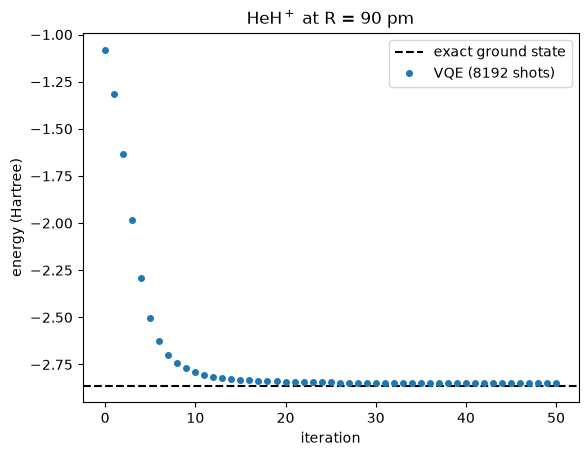

In [8]:
fig, ax = plt.subplots()
ax.axhline(E_exact, ls="--", c="k", label="exact ground state")
ax.plot(energies, "o", ms=4, label="VQE (8192 shots)")
ax.set_xlabel("iteration")
ax.set_ylabel("energy (Hartree)")
ax.set_title(f"HeH$^+$ at R = {R} pm")
ax.legend()
plt.show()

VQE gets close to the exact energy, but not all the way there. Two things limit it:

* **Shot noise.** Each energy has a statistical error of about $0.01$ Hartree with 8192 shots. The finite-difference gradient divides differences of noisy energies by $2c$, which amplifies the noise. That is why we use a fairly large step $c = 0.1\pi$.
* **Local minima.** Even with *exact* expectation values (`shots=None`), gradient descent from these initial angles gets stuck about $0.009$ Hartree above the ground state. A different starting point can reach the true minimum.

For chemistry, the target is usually *chemical accuracy*, $1.6\times10^{-3}$ Hartree. We are not there yet!

## On a (simulated) noisy device

Finally, we evaluate the energy at our optimised angles on a fake IBM device, with realistic noise. We reuse our hand-made measurement circuits and `energy_from_counts`, together with `qiskit_ibm_runtime`'s Sampler. This is **exactly** the code you would use on real hardware: only the `backend` changes.

In [9]:
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit_ibm_runtime.fake_provider import FakeFez

backend = FakeFez()
pm = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=1)
device_circuits = pm.run(measurement_circuits)          # transpile all four measurement circuits

device_sampler = Sampler(mode=backend)
device_sampler.options.simulator.seed_simulator = 4041   # fake backends only: reproducible noise
E_noisy = energy_by_hand(theta_opt, sampler=device_sampler, circuits=device_circuits)

print(f"Noisy fake device: E = {E_noisy:.4f}")
print(f"Noiseless:         E = {E_final_exact:.4f}")
print(f"Exact:             E = {E_exact:.4f}")

Noisy fake device: E = -2.8403
Noiseless:         E = -2.8513
Exact:             E = -2.8626


Noise pushes the measured energy **up**, away from the ground state. Gate and readout errors mix in other states, which have higher energy. Reducing this effect is the subject of *error mitigation*. To run on a real device, see [Running on real quantum computers](../content/outline/hardwareAccess.md) and replace `backend = FakeFez()` with your real backend.

````{admonition} Try this
:class: tip
1. (Exercise 4.1.3) Change the ansatz to the alternative circuit in the lecture notes. Does it reach the ground state?
2. Start from random initial angles a few times. Do you always reach the same energy? Can you reach chemical accuracy?
3. How does the final error depend on `shots`? Try 100, 1000 and 100 000.
4. (Exercise 5.2, after Lecture 5) Replace the finite-difference gradient with SPSA and/or the parameter-shift rule. How many energy evaluations does each method need per iteration?
````